# UTS Graf Sains Data — Chiara Dewi Chatlina
**Nama:** Chiara Dewi Chatlina 

**NIM:** 23031554170

**Database Neo4j:** `utsgsd`  

**Dataset:** RetailRocket (`events.csv`)

## Periode waktu yang digunakan

- **P1 (training):** 17 Mei 2015 – 19 Juni 2015
- **P2 (testing):** 8 Juli 2015 – 11 Agustus 2015


In [ ]:
%pip install "neo4j>=5.20" pandas numpy scipy scikit-learn networkx matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## NOMOR 1 — Library, Konfigurasi, Periode yang digunakan

In [ ]:
import math, random, subprocess, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from neo4j import GraphDatabase, RoutingControl

# Konfigurasi 
NEO4J_URI  = "neo4j://127.0.0.1:7687"
NEO4J_AUTH = ("neo4j", "password")
NEO4J_DB   = "utsgsd"

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)

# Periode 
P1 = ("2015-05-17", "2015-06-19")   # Chiara: P1 training
P2 = ("2015-07-08", "2015-08-11")   # Chiara: P2 testing

SEED       = 2026      # ganti dengan angka milik Anda (mis. 4 digit akhir NIM) -> reproducible
BATCH_SIZE = 20_000    # ukuran batch impor ke Neo4j
EVENT_WEIGHT = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}  # bobot interaksi di VSM

MIN_ITEMS_PER_USER = 2       # user aktif = minimal berinteraksi dgn 2 item berbeda
MAX_USERS          = 20_000  # batasi jumlah user di VSM agar ringan (None = semua)

K, N_ADS, TOP_N = 5, 3, 5    # k tetangga, 3 item diiklankan, evaluasi @5
EXCLUDE_SEEN = True          # jangan rekomendasikan item yang sudah pernah disentuh user di P1

d:\SEMESTER 7\GRAF\uts-gsd\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## NOMOR 2 — Unduh Data

In [3]:
URL = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
zip_path = DATA_DIR / "ecommerce-dataset.zip"

if not (DATA_DIR / "events.csv").exists():
    subprocess.run(["curl", "-L", "-o", str(zip_path), URL], check=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extract("events.csv", DATA_DIR)
print("events.csv siap:", (DATA_DIR / "events.csv").exists())

events.csv siap: True


## NOMOR 3 — Wrangling Data & EDA

In [4]:
events = pd.read_csv(DATA_DIR / "events.csv")
events["dt"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
print("Rentang data:", events["dt"].min(), "->", events["dt"].max(), "| baris:", len(events))

def to_ms(date_str, end_of_day=False):
    ts = pd.Timestamp(date_str, tz="UTC")
    if end_of_day:
        ts += pd.Timedelta(days=1)          # batas akhir inklusif
    return int(ts.timestamp() * 1000)

def filter_period(df, period):
    start, end = period
    m = (df["timestamp"] >= to_ms(start)) & (df["timestamp"] < to_ms(end, True))
    return df.loc[m]

assert pd.Timestamp(P1[1]) < pd.Timestamp(P2[0]), "P1 harus berakhir sebelum P2 dimulai"

COLS = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
def prep(df):
    out = df[COLS].copy()
    out["transactionid"] = out["transactionid"].astype("Int64")   # tanpa '.0' saat disimpan
    return out

p1 = prep(filter_period(events, P1))
p2 = prep(filter_period(events, P2))
assert len(p1) > 0 and len(p2) > 0, "Periode kosong - cek rentang data di atas!"

p1.to_csv(DATA_DIR / "events_p1_train.csv", index=False)
p2.to_csv(DATA_DIR / "events_p2_test.csv", index=False)

summary = pd.DataFrame({
    name: {"baris": len(df), "visitor unik": df["visitorid"].nunique(),
           "item unik": df["itemid"].nunique(), **df["event"].value_counts().to_dict()}
    for name, df in [(f"P1 train {P1}", p1), (f"P2 test {P2}", p2)]
})
display(summary)

Rentang data: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00 | baris: 2756101


,"P1 train ('2015-05-17', '2015-06-19')","P2 test ('2015-07-08', '2015-08-11')"
baris,708284,752310
visitor unik,366707,413812
item unik,126576,130808
view,685428,727121
addtocart,17218,19062
transaction,5638,6127


### NOMOR 4 — Impor P1 ke Neo4j & komposisi subgraph

In [5]:
# [NEO4J] NOMOR 3 — koneksi, pemeriksaan database, dan pembuatan constraint
from neo4j import GraphDatabase

# 1. Konfigurasi koneksi Neo4j Desktop "chiara"
NEO4J_URI = "bolt://127.0.0.1:7687"
NEO4J_AUTH = ("neo4j", "12345678")
NEO4J_DB = "utsgsd"  # database yang berstatus online

# 2. Membuat koneksi
driver = GraphDatabase.driver(NEO4J_URI, auth=NEO4J_AUTH)

try:
    # 3. Memeriksa koneksi
    driver.verify_connectivity()
    print("Koneksi ke Neo4j chiara berhasil!")

    # 4. Memeriksa database yang tersedia
    with driver.session(database="system") as system_session:
        databases = system_session.run("SHOW DATABASES").data()

    print("\nDatabase yang tersedia:")
    for db in databases:
        print(f"- {db['name']} | Status: {db['currentStatus']}")

    # 5. Pastikan database yang dipilih tersedia dan online
    available = {db["name"]: db["currentStatus"] for db in databases}
    if NEO4J_DB not in available:
        raise ValueError(f"Database {NEO4J_DB!r} tidak ditemukan pada daftar database.")
    if available[NEO4J_DB].lower() != "online":
        raise RuntimeError(
            f"Database {NEO4J_DB!r} belum online (status: {available[NEO4J_DB]})."
        )

    # 6. Buat constraint pada database yang dipilih
    def create_constraints(session):
        session.run("""
            CREATE CONSTRAINT visitor_id IF NOT EXISTS
            FOR (v:Visitor)
            REQUIRE v.visitorId IS UNIQUE
        """).consume()
        session.run("""
            CREATE CONSTRAINT item_id IF NOT EXISTS
            FOR (i:Item)
            REQUIRE i.itemId IS UNIQUE
        """).consume()

    with driver.session(database=NEO4J_DB) as session:
        create_constraints(session)

    print(f"\nDatabase aktif: {NEO4J_DB}")
    print("Constraint Visitor dan Item berhasil disiapkan.")

except Exception as e:
    print("\nTerjadi kesalahan:", type(e).__name__)
    print("Detail:", str(e))
    raise


Koneksi ke Neo4j chiara berhasil!

Database yang tersedia:
- movie | Status: online
- movielens | Status: online
- neo4j | Status: quarantined
- system | Status: online
- utsgsd | Status: online

Database aktif: utsgsd
Constraint Visitor dan Item berhasil disiapkan.


In [ ]:
def make_query(rel, props):
    return f"""
    UNWIND $batch AS row
    MERGE (v:Visitor {{visitorId: row.visitorid}})
    MERGE (i:Item {{itemId: row.itemid}})
    CREATE (v)-[:{rel} {{{props}}}]->(i)
    """

CYPHER_BY_EVENT = {
    "view":        make_query("VIEWED", "timestamp: row.timestamp"),
    "addtocart":   make_query("ADDED_TO_CART", "timestamp: row.timestamp"),
    "transaction": make_query("BOUGHT", "timestamp: row.timestamp, transactionId: row.transactionid"),
}

def import_batch(tx, chunk):
    for ev, q in CYPHER_BY_EVENT.items():
        sub = chunk[chunk["event"] == ev]
        if sub.empty:
            continue
        cols = ["visitorid", "itemid", "timestamp"] + (["transactionid"] if ev == "transaction" else [])
        tx.run(q, batch=sub[cols].astype("int64").to_dict("records"))

csv_path = DATA_DIR / "events_p1_train.csv"
total_chunks = math.ceil(len(p1) / BATCH_SIZE)
with driver.session(database=NEO4J_DB) as session:
    for chunk in tqdm(pd.read_csv(csv_path, chunksize=BATCH_SIZE), total=total_chunks, desc="Mengimpor batch"):
        session.execute_write(import_batch, chunk)
print("Proses impor berhasil.")

Mengimpor batch: 100%|██████████| 36/36 [00:35<00:00,  1.01it/s]

Proses impor berhasil.


In [7]:
# [NEO4J] komposisi subgraph via Python API
def cypher_df(query, **params):
    records, _, _ = driver.execute_query(query, routing_=RoutingControl.READ, database_=NEO4J_DB, **params)
    return pd.DataFrame([r.data() for r in records])

Q_NODES = """
MATCH (n)
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_RELS = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
Q_PATTERN = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(DISTINCT v) AS visitor_unik, count(DISTINCT i) AS item_unik
"""
display(cypher_df(Q_NODES)); display(cypher_df(Q_RELS)); display(cypher_df(Q_PATTERN))

,jenis_simpul,jumlah
0,Visitor,366707
1,Item,126576


,jenis_relasi,jumlah
0,VIEWED,685428
1,ADDED_TO_CART,17218
2,BOUGHT,5638


,relasi,visitor_unik,item_unik
0,VIEWED,365995,126401
1,ADDED_TO_CART,9601,9048
2,BOUGHT,3022,3967


### Penjelasan Cypher dan Interpretasi

Query Cypher digunakan untuk menghitung jumlah simpul `Visitor` dan `Item`, jumlah relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`, serta jumlah user dan item yang terlibat dalam setiap relasi. Hasil query diambil melalui Python API `driver.execute_query()` dan diubah menjadi DataFrame agar lebih mudah dianalisis.

Interpretasi hasil: Relasi `VIEWED` menunjukkan aktivitas melihat produk, `ADDED_TO_CART` menunjukkan aktivitas menambahkan produk ke keranjang, sedangkan `BOUGHT` menunjukkan transaksi pembelian. Perbandingan jumlah ketiganya dapat digunakan untuk melihat pola interaksi pengguna dan kecenderungan aktivitas belanja. Rasio aktual perlu disesuaikan dengan angka hasil run notebook kamu.

### NOMOR 5 — Vector Space Modelling (VSM)
Matriks interaksi user–item dibangun dari P1: 
tiap sel = jumlah bobot event (`view`=1, `addtocart`=3, `transaction`=5).
1. **VSM User**: tiap user = vektor di ruang berdimensi **jumlah item** → matriks `X` (user × item)
2. **VSM Item**: tiap item = vektor di ruang berdimensi **jumlah user** → matriks `Xᵀ` (item × user)

In [8]:
w = p1["event"].map(EVENT_WEIGHT)
inter = p1.assign(w=w).groupby(["visitorid", "itemid"], as_index=False)["w"].sum()

# user aktif + sampling reproducible
n_items_user = inter.groupby("visitorid")["itemid"].nunique()
active = n_items_user[n_items_user >= MIN_ITEMS_PER_USER].index.to_numpy()
if MAX_USERS and len(active) > MAX_USERS:
    active = np.random.default_rng(SEED).choice(active, MAX_USERS, replace=False)
inter = inter[inter["visitorid"].isin(active)]

user_ids, u_codes = np.unique(inter["visitorid"].to_numpy(), return_inverse=True)
item_ids, i_codes = np.unique(inter["itemid"].to_numpy(), return_inverse=True)
X = sp.csr_matrix((inter["w"].to_numpy(), (u_codes, i_codes)), shape=(len(user_ids), len(item_ids)))
X_item = X.T.tocsr()

user_index = {int(u): i for i, u in enumerate(user_ids)}
item_index = {int(i): j for j, i in enumerate(item_ids)}
print("X (user x item) :", X.shape, "| X_item (item x user):", X_item.shape)

X (user x item) : (20000, 34048) | X_item (item x user): (34048, 20000)


In [9]:
def describe_matrix(M, name, entity):
    M = M.tocsr()
    n, m = M.shape
    rownnz = np.diff(M.indptr)
    return {
        "VSM": name, "entitas (baris)": entity, "shape": f"{n} x {m}", "dimensi vektor": m,
        "nnz": M.nnz, "density (%)": 100 * M.nnz / (n * m),
        "rata2 nnz/baris": rownnz.mean(), "median nnz/baris": float(np.median(rownnz)), "max nnz/baris": int(rownnz.max()),
        "memori (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "rata2 norma L2": float(np.sqrt(M.multiply(M).sum(axis=1)).mean()),
    }

def plot_vsm_graph(M, row_ids, col_ids, row_prefix, col_prefix, n_rows=12, max_cols=6, title=""):
    """Plot networkx (bipartit) dari sampel baris matriks VSM dan fitur yang tidak nol."""
    rnd = random.Random(SEED)
    G = nx.Graph()
    for r in rnd.sample(range(M.shape[0]), min(n_rows, M.shape[0])):
        row = M[r]
        order = np.argsort(-row.data)[:max_cols]
        for c, val in zip(row.indices[order], row.data[order]):
            G.add_edge(f"{row_prefix}{row_ids[r]}", f"{col_prefix}{col_ids[c]}", weight=val)
    pos = nx.spring_layout(G, seed=SEED)
    colors = ["tab:blue" if n.startswith(row_prefix) else "tab:orange" for n in G.nodes]
    plt.figure(figsize=(9, 6))
    nx.draw(G, pos, node_color=colors, node_size=250, font_size=6, with_labels=True, edge_color="lightgray")
    plt.title(title); plt.show()
    print(f"Sampel graf: {G.number_of_nodes()} simpul, {G.number_of_edges()} sisi")

def plot_nnz_hist(M, title):
    rownnz = np.diff(M.tocsr().indptr)
    plt.figure(figsize=(6, 3)); plt.hist(rownnz, bins=50, log=True)
    plt.xlabel("jumlah elemen tak-nol per vektor"); plt.ylabel("frekuensi (log)"); plt.title(title); plt.show()

,0
VSM,User
entitas (baris),Visitor
shape,20000 x 34048
dimensi vektor,34048
nnz,71434
density (%),0.01049
rata2 nnz/baris,3.5717
median nnz/baris,2.0
max nnz/baris,974
memori (MB),0.937212


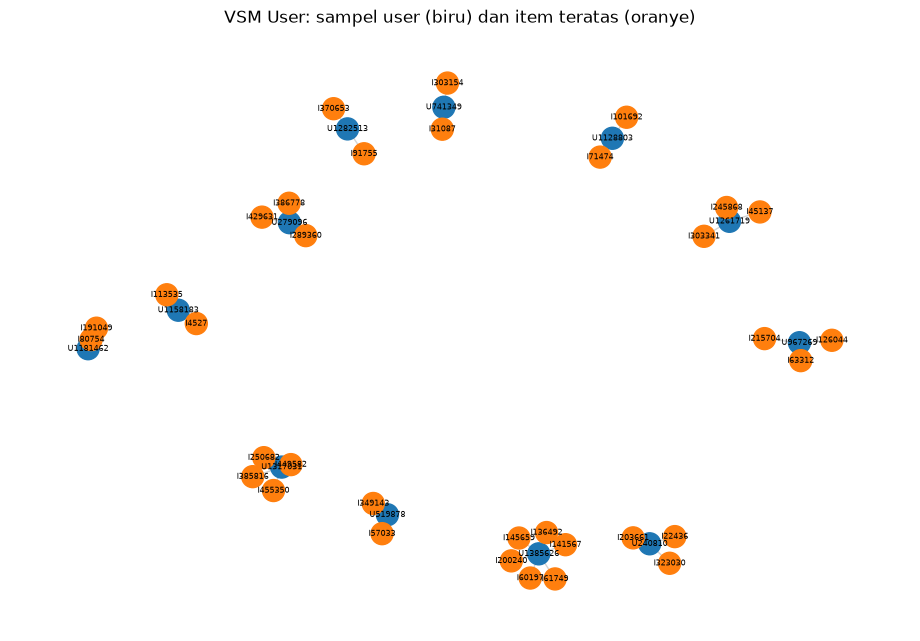

Sampel graf: 46 simpul, 34 sisi


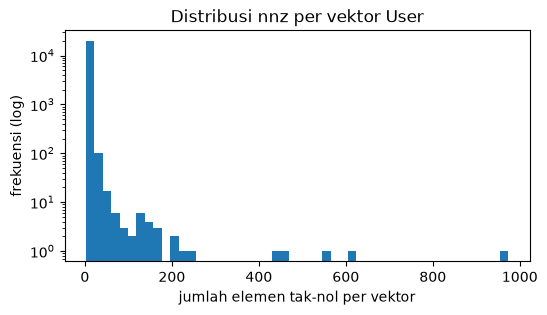

In [10]:
# 2.1.4 VSM User
display(pd.DataFrame([describe_matrix(X, "User", "Visitor")]).T)
plot_vsm_graph(X, user_ids, item_ids, "U", "I", title="VSM User: sampel user (biru) dan item teratas (oranye)")
plot_nnz_hist(X, "Distribusi nnz per vektor User")

,0
VSM,Item
entitas (baris),Item
shape,34048 x 20000
dimensi vektor,20000
nnz,71434
density (%),0.01049
rata2 nnz/baris,2.098038
median nnz/baris,1.0
max nnz/baris,100
memori (MB),0.993404


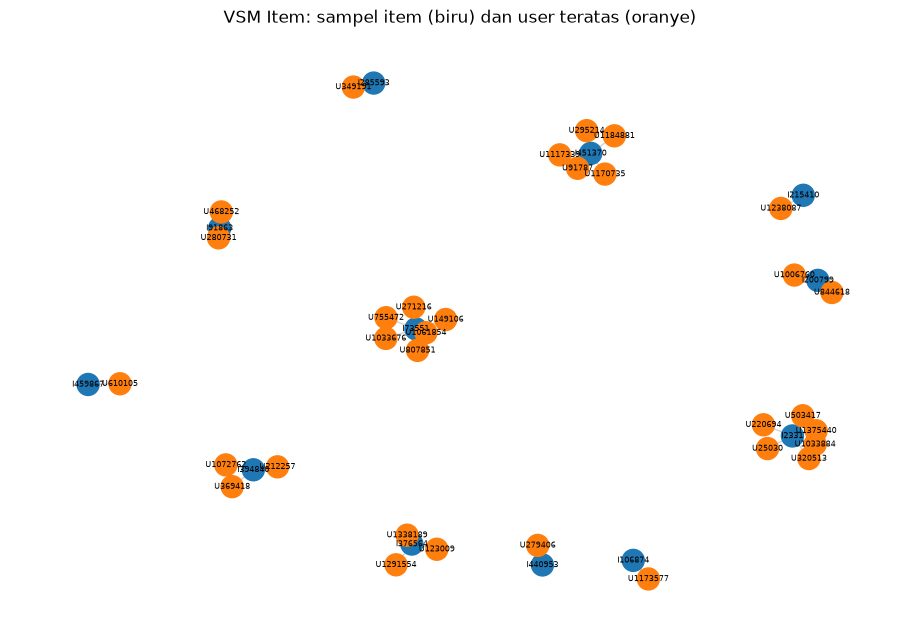

Sampel graf: 44 simpul, 32 sisi


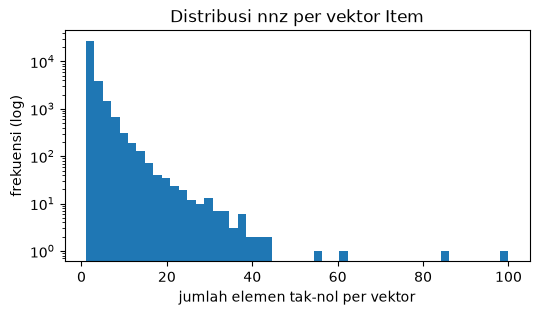

In [11]:
# 2.1.5 VSM Item
display(pd.DataFrame([describe_matrix(X_item, "Item", "Item")]).T)
plot_vsm_graph(X_item, item_ids, user_ids, "I", "U", title="VSM Item: sampel item (biru) dan user teratas (oranye)")
plot_nnz_hist(X_item, "Distribusi nnz per vektor Item")

VSM User memiliki shape 20.000 × 34.048, sedangkan VSM Item memiliki shape 34.048 × 20.000. Kedua matriks memiliki density 0,01049% dan sparsity 99,98951%. Rata-rata elemen tak-nol per vektor User adalah 3,57 (median 2, maksimum 974), sedangkan VSM Item memiliki rata-rata 2,10 (median 1, maksimum 100). Hal ini menunjukkan bahwa mayoritas user hanya berinteraksi dengan sedikit item. Graf bipartit pada plot sampel memperlihatkan 46 simpul dan 34 sisi untuk VSM User, serta 44 simpul dan 32 sisi untuk VSM Item.

### NOMOR 6 — Proyeksi mana yang lebih baik?
Graf bipartit `User–Item` diproyeksikan menjadi:
- **proyeksi user–user**: `B·Bᵀ` (dua user terhubung jika memakai ≥1 item yang sama)
- **proyeksi item–item**: `Bᵀ·B` (dua item terhubung jika disentuh ≥1 user yang sama)

dengan `B` = versi biner dari `X`. Dibandingkan jumlah simpul, jumlah sisi, density, derajat rata-rata, dan waktu komputasi.

In [12]:
def projection_stats(M, name, block=500):
    B = M.tocsr().copy(); B.data[:] = 1
    BT = B.T.tocsr()
    t0 = time.time(); total_nnz = 0
    for s in range(0, B.shape[0], block):           # per-blok agar hemat memori
        total_nnz += (B[s:s + block] @ BT).nnz
    n = B.shape[0]
    edges = (total_nnz - n) // 2                    # buang diagonal, graf tak berarah
    return {"proyeksi": name, "simpul": n, "sisi": edges,
            "density (%)": 100 * 2 * edges / (n * (n - 1)),
            "derajat rata2": 2 * edges / n, "dimensi vektor": B.shape[1],
            "waktu (s)": time.time() - t0}

proj_df = pd.DataFrame([projection_stats(X, "user-user"), projection_stats(X_item, "item-item")]).set_index("proyeksi")
display(proj_df)

# >>> Tentukan pilihan berdasarkan tabel di atas (simpul lebih sedikit, density/waktu lebih kecil = lebih efisien) <<<
PROJECTION = "user"      # "user" atau "item"

,simpul,sisi,density (%),derajat rata2,dimensi vektor,waktu (s)
proyeksi,,,,,,
user-user,20000,142034,0.071021,14.203400,34048,0.011018
item-item,34048,1425378,0.245918,83.727561,20000,0.027694


Proyeksi User–User dipilih karena lebih efisien, dengan 20.000 simpul, 142.034 sisi, dan waktu komputasi 0,011 detik. Sementara itu, proyeksi Item–Item memiliki 34.048 simpul, 1.425.378 sisi, dan waktu 0,028 detik. Dari sisi efektivitas, User–User dapat membantu menemukan pengguna dengan pola interaksi serupa. Namun, karena matriks sangat sparse, kemiripan user perlu dievaluasi melalui hasil rekomendasi KNN.

### NOMOR 7 — Similarity pada graf proyeksi, sebelum & sesudah
Similarity = **cosine** antar vektor VSM (sama dengan bobot proyeksi ternormalisasi). Record acuan = simpul dengan derajat tertinggi.

In [13]:
if PROJECTION == "user":
    M, ids, LABEL, KEY = X, user_ids, "Visitor", "visitorId"
else:
    M, ids, LABEL, KEY = X_item, item_ids, "Item", "itemId"

Mn = normalize(M)                                    # L2-normalisasi -> dot product = cosine
ref_idx = int(np.argmax(np.diff(M.indptr)))          # record acuan: derajat tertinggi
ref_id = int(ids[ref_idx])

sims = (Mn[ref_idx] @ Mn.T).toarray().ravel()
sims[ref_idx] = -1                                   # abaikan diri sendiri
top = np.argsort(-sims)[:5]
pairs = [{"src": ref_id, "dst": int(ids[j]), "score": float(sims[j])} for j in top]

print(f"Proyeksi: {PROJECTION} | acuan {LABEL} {ref_id}")
display(pd.DataFrame(pairs))

Proyeksi: user | acuan Visitor 163561


,src,dst,score
0,163561,918766,0.132248
1,163561,349885,0.128226
2,163561,1080760,0.128226
3,163561,704347,0.119512
4,163561,899717,0.116892


SEBELUM similarity


,jenis_relasi,jumlah
0,VIEWED,685428
1,ADDED_TO_CART,17218
2,BOUGHT,5638


Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `score` does not exist in database `utsgsd`. Verify that the spelling is correct.', position=<SummaryInputPosition line=3, column=107, offset=181>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 181, 'line': 3, 'column': 107}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nMATCH (a:Visitor {visitorId: $ref})-[r]-(n) WHERE type(r) <> 'SIMILAR_TO'\nRETURN a.visitorId AS src, type(r) AS rel, labels(n)[0] AS lbl, coalesce(n.visitorId, n.itemId) AS dst, r.score AS score\nLIMIT 15\nUNION ALL\nMATCH (a:Visitor {visitorId: $ref})-[r:SIMILAR_TO]->(n)\nRETURN a.visitorId AS src, type(r) 

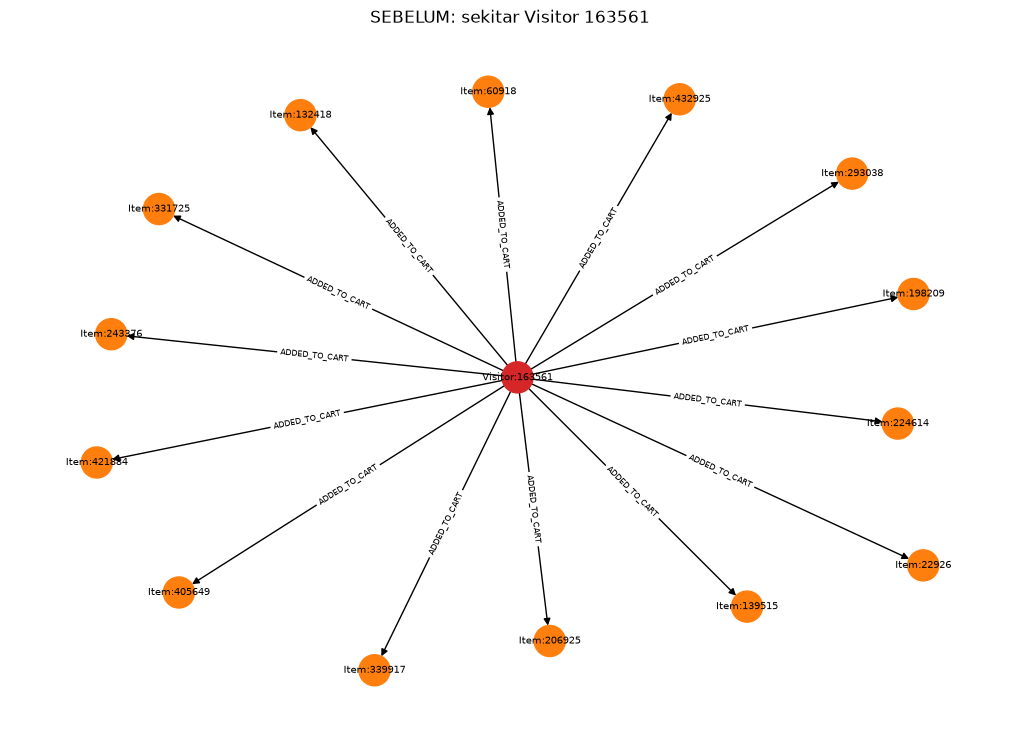

SESUDAH similarity


,jenis_relasi,jumlah
0,VIEWED,685428
1,ADDED_TO_CART,17218
2,BOUGHT,5638
3,SIMILAR_TO,5


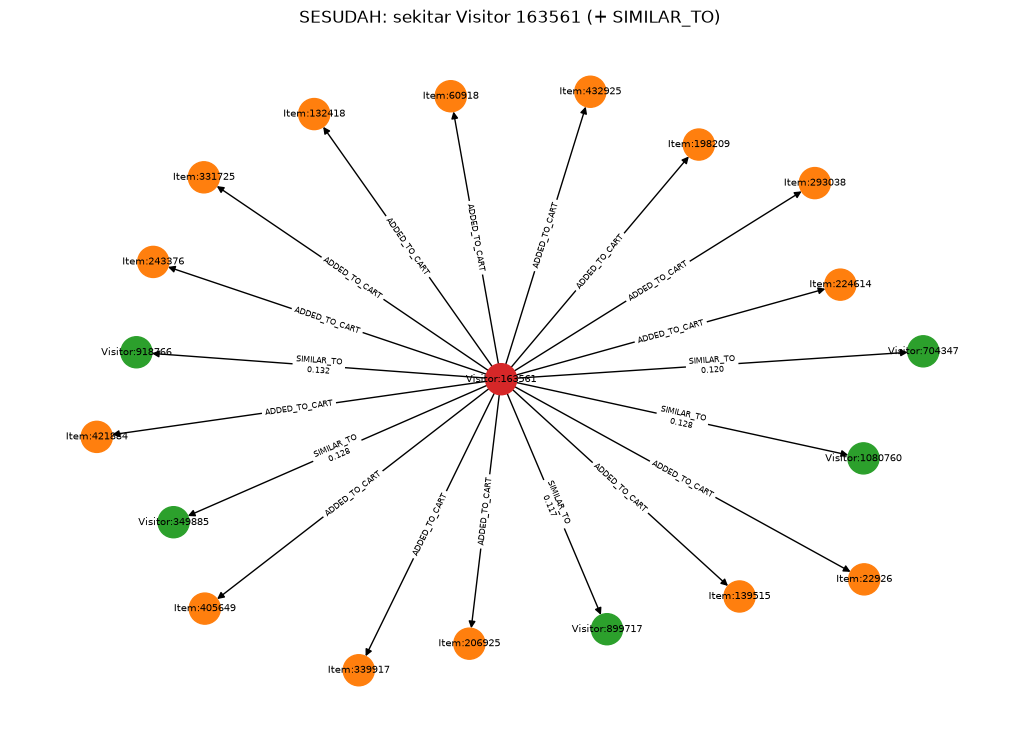

,id,similarity
0,918766,0.132248
1,1080760,0.128226
2,349885,0.128226
3,704347,0.119512
4,899717,0.116892


In [14]:
# [NEO4J] sebelum & sesudah similarity
def count_rels():
    return cypher_df("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC")

EDGE_Q = f"""
MATCH (a:{LABEL} {{{KEY}: $ref}})-[r]-(n) WHERE type(r) <> 'SIMILAR_TO'
RETURN a.{KEY} AS src, type(r) AS rel, labels(n)[0] AS lbl, coalesce(n.visitorId, n.itemId) AS dst, r.score AS score
LIMIT 15
UNION ALL
MATCH (a:{LABEL} {{{KEY}: $ref}})-[r:SIMILAR_TO]->(n)
RETURN a.{KEY} AS src, type(r) AS rel, labels(n)[0] AS lbl, coalesce(n.visitorId, n.itemId) AS dst, r.score AS score
"""

def draw_edges(df, title):
    G = nx.DiGraph(); labels = {}
    for r in df.itertuples():
        a, b = f"{LABEL}:{r.src}", f"{r.lbl}:{r.dst}"
        G.add_edge(a, b)
        labels[(a, b)] = r.rel if pd.isna(r.score) else f"{r.rel}\n{r.score:.3f}"
    pos = nx.spring_layout(G, seed=SEED)
    colors = ["tab:red" if n == f"{LABEL}:{ref_id}" else ("tab:green" if n.startswith(LABEL) else "tab:orange") for n in G.nodes]
    plt.figure(figsize=(10, 7))
    nx.draw(G, pos, node_color=colors, node_size=500, font_size=7, with_labels=True, arrows=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=6)
    plt.title(title); plt.show()

# --- SEBELUM ---
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_=NEO4J_DB)
print("SEBELUM similarity"); display(count_rels())
draw_edges(cypher_df(EDGE_Q, ref=ref_id), f"SEBELUM: sekitar {LABEL} {ref_id}")

# --- TULIS similarity ke graf (7b) ---
WRITE_Q = f"""
UNWIND $pairs AS p
MATCH (a:{LABEL} {{{KEY}: p.src}}), (b:{LABEL} {{{KEY}: p.dst}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = p.score, s.metric = 'cosine', s.projection = $proj
"""
driver.execute_query(WRITE_Q, pairs=pairs, proj=PROJECTION, database_=NEO4J_DB)

# --- SESUDAH ---
print("SESUDAH similarity"); display(count_rels())
draw_edges(cypher_df(EDGE_Q, ref=ref_id), f"SESUDAH: sekitar {LABEL} {ref_id} (+ SIMILAR_TO)")

# --- 7a: 5 record dengan similarity tertinggi, langsung dari graf ---
TOP5_Q = f"""
MATCH (a:{LABEL} {{{KEY}: $ref}})-[s:SIMILAR_TO]->(b:{LABEL})
RETURN b.{KEY} AS id, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
display(cypher_df(TOP5_Q, ref=ref_id))

## 2.2 — Analytics — KNN Recommender, Hit@5, NDCG@5

In [15]:
p2_use = p2[p2["visitorid"].isin(user_index)]
gt_raw = p2_use.groupby("visitorid")["itemid"].agg(lambda s: set(int(i) for i in s)).to_dict()

def seen_items(uid):
    return set(int(i) for i in item_ids[X[user_index[uid]].indices])

def ground_truth(uid):
    s = {i for i in gt_raw.get(uid, set()) if i in item_index}     # hanya item yang bisa direkomendasikan
    return s - seen_items(uid) if EXCLUDE_SEEN else s

eligible = sorted(int(u) for u in gt_raw if ground_truth(int(u)))
print("User eligible:", len(eligible), "dari", len(user_ids))

target_uid = random.Random(SEED).choice(eligible)
print("User terpilih (acak, seed =", SEED, "):", target_uid)

User eligible: 695 dari 20000
User terpilih (acak, seed = 2026 ): 234502


In [16]:
# KNN berbasis user (cosine, brute force pada matriks sparse)
knn = NearestNeighbors(n_neighbors=K + 1, metric="cosine", algorithm="brute").fit(X)

def recommend_user_knn(uid, k=K, n=TOP_N):
    u = user_index[uid]
    dist, idx = knn.kneighbors(X[u], n_neighbors=k + 1)
    idx, dist = idx[0], dist[0]
    keep = idx != u                                   # buang diri sendiri
    nbrs, sims_k = idx[keep][:k], 1 - dist[keep][:k]
    scores = np.asarray(X[nbrs].T @ sims_k).ravel()    # skor item = sum(sim_tetangga * bobot interaksi)
    if EXCLUDE_SEEN:
        scores[X[u].indices] = -np.inf
    order = [j for j in np.argsort(-scores)[:n] if scores[j] > 0]
    recs = [(int(item_ids[j]), float(scores[j])) for j in order]
    return recs, [(int(user_ids[a]), float(s)) for a, s in zip(nbrs, sims_k)]

# Varian berbasis item (dipakai jika PROJECTION == "item")
Xi = normalize(X_item)
def recommend_item_knn(uid, k=K, n=TOP_N, max_seen=50):
    u = user_index[uid]; row = X[u]
    order = np.argsort(-row.data)[:max_seen]
    scores = np.zeros(X.shape[1])
    for j, wj in zip(row.indices[order], row.data[order]):
        s = (Xi[j] @ Xi.T).toarray().ravel(); s[j] = 0
        nn = np.argpartition(-s, k)[:k]
        scores[nn] += s[nn] * wj
    if EXCLUDE_SEEN:
        scores[row.indices] = -np.inf
    top = [j for j in np.argsort(-scores)[:n] if scores[j] > 0]
    return [(int(item_ids[j]), float(scores[j])) for j in top], None

recommend = recommend_user_knn if PROJECTION == "user" else recommend_item_knn

# Metrik (relevansi biner)
def hit_at_k(rec, rel, k):
    return int(any(i in rel for i in rec[:k]))

def ndcg_at_k(rec, rel, k):
    dcg = sum(1 / math.log2(r + 2) for r, i in enumerate(rec[:k]) if i in rel)
    idcg = sum(1 / math.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

In [17]:
# 2.2.1 a-b : KNN (k=5) untuk user terpilih -> 3 item yang diiklankan
recs, nbrs = recommend(target_uid, k=K, n=TOP_N)
rec_items = [i for i, _ in recs]
rel = ground_truth(target_uid)

if nbrs:
    print(f"{K} tetangga terdekat user {target_uid}:")
    display(pd.DataFrame(nbrs, columns=["visitorId", "cosine_sim"]))
print(f"\n== 3 item yang diiklankan (k={K}) ==")
display(pd.DataFrame(recs[:N_ADS], columns=["itemId", "skor"]))

# 2.2.2 a-b : evaluasi pada top-5
print("Rekomendasi top-5      :", rec_items)
print("Item relevan di P2     :", sorted(rel))
print("Posisi hit (1-indexed) :", [r + 1 for r, i in enumerate(rec_items[:TOP_N]) if i in rel])
print(f"Hit@5  = {hit_at_k(rec_items, rel, 5)}")
print(f"NDCG@5 = {ndcg_at_k(rec_items, rel, 5):.4f}")

5 tetangga terdekat user 234502:


,visitorId,cosine_sim
0,1163675,0.348155
1,316510,0.334497
2,755418,0.227921
3,831695,0.213201
4,1197393,0.213201



== 3 item yang diiklankan (k=5) ==


,itemId,skor
0,230293,0.668994
1,433585,0.348155
2,316624,0.348155


Rekomendasi top-5      : [230293, 433585, 316624, 275097, 128449]
Item relevan di P2     : [13397, 30393, 38021, 131703, 202626, 252723, 258999, 282244, 344388, 429759]
Posisi hit (1-indexed) : []
Hit@5  = 0
NDCG@5 = 0.0000


In [ ]:
sample_users = random.Random(SEED + 1).sample(eligible, min(300, len(eligible)))
rows = []
for uid in tqdm(sample_users, desc="Evaluasi"):
    r, _ = recommend(uid)
    ri = [i for i, _ in r]; rl = ground_truth(uid)
    rows.append((hit_at_k(ri, rl, 5), ndcg_at_k(ri, rl, 5)))
res = pd.DataFrame(rows, columns=["Hit@5", "NDCG@5"])
print(f"{len(res)} user -> mean Hit@5 = {res['Hit@5'].mean():.4f} | mean NDCG@5 = {res['NDCG@5'].mean():.4f}")

Evaluasi: 100%|██████████| 300/300 [00:00<00:00, 325.32it/s]

300 user -> mean Hit@5 = 0.0367 | mean NDCG@5 = 0.0151


In [19]:
# [NEO4J] tutup koneksi
driver.close()